<a href="https://colab.research.google.com/github/Arsxcn/my-website/blob/main/Assignment2_DigitVision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DigitVision AI · Option B

## Can synthetic data improve handwritten digit recognition?

**Computer vision.** Given an 8 × 8 image of a handwritten digit, classify it as 0 through 9. We test whether small rotations, shifts, and noise improve recognition when labeled training data is limited.

| Condition | Training set | Test set |
|:--|:--|:--|
| Before augmentation | 300 original images | 450 original images |
| After augmentation | The same 300 originals + 1,200 synthetic images | The same 450 originals |

**How to run.** Open the notebook in [Google Colab](https://colab.research.google.com/) and select **Runtime → Run all**. A CPU runtime is sufficient. The notebook includes the plots and results from a verified run. To try the interactive demo, run the notebook and open the Gradio link in the final cell. [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)

## 1. Libraries and setup

NumPy stores images as arrays. SciPy applies the image transformations. Scikit-learn trains and evaluates the models. Pandas and Matplotlib display the tables and plots. Pillow prepares drawings from the browser, and Gradio provides the interface. We pin package versions and use a fixed random seed so the experiment can be repeated.

In [ ]:
# Install the pinned package versions in the current notebook environment.
%pip install -q numpy==2.4.6 scipy==1.16.3 scikit-learn==1.6.1 pandas==2.2.3 matplotlib==3.10.0 pillow==11.3.0 gradio==6.31.0

In [ ]:
# Import the libraries for image processing, training, and visualization.
import sys
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from PIL import Image
from scipy.ndimage import rotate, shift
from sklearn.datasets import load_digits
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Display plots directly below the cells.
%matplotlib inline

# Set the split sizes, pixel intensity range, and augmentation parameters.
SEED = 42
N_TRAIN = 300
N_TEST = 450
N_VARIANTS = 4
DIGIT_LABELS = np.arange(10)
MAX_PIXEL = 16
MAX_ANGLE = 10
MAX_SHIFT = 0.35
NOISE_SIGMA = 0.25
IN_COLAB = "google.colab" in sys.modules

# Use consistent fonts and colors across the figures.
BEFORE_COLOR = "#31547a"
AFTER_COLOR = "#00806a"
TEXT_COLOR = "#172e44"
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titleweight": "semibold",
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Print the package versions so results can be compared across runs.
packages = ("numpy", "scipy", "scikit-learn", "pandas", "matplotlib", "pillow", "gradio")
print(f"Python {sys.version.split()[0]}")
print(" · ".join(f"{name} {version(name)}" for name in packages))

Python 3.13.18
numpy 2.4.6 · scipy 1.16.3 · scikit-learn 1.6.1 · pandas 2.2.3 · matplotlib 3.10.0 · pillow 11.3.0 · gradio 6.31.0


## 2. Dataset and fixed test set

The built-in **Digits** dataset contains 1,797 labeled images. Each image has 64 pixels with intensity values from 0 to 16. [Scikit-learn Digits documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)

We first hold out 450 images for testing. From the remaining images, we select 300 for training and leave 1,047 unused. Both splits are stratified to keep the class proportions approximately the same. We check that the three sets have no overlapping indices.

,0,1,2,3,4,5,6,7,8,9,Total
Training,30,30,30,31,30,30,30,30,29,30,300
Test,45,46,44,46,45,46,45,45,43,45,450
Unused,103,106,103,106,106,106,106,104,102,105,1047


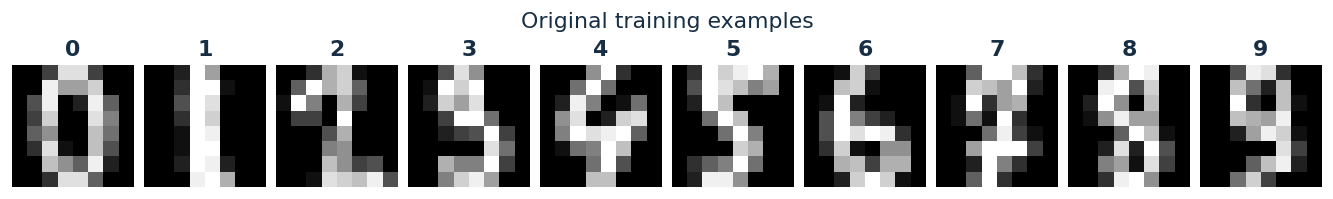

In [ ]:
# Load the images and labels, then split their row indices.
digits = load_digits()
images, labels = digits.images, digits.target
all_indices = np.arange(len(labels))

pool_indices, test_indices = train_test_split(
    all_indices, test_size=N_TEST, stratify=labels, random_state=SEED
)
train_indices, unused_indices = train_test_split(
    pool_indices, train_size=N_TRAIN, stratify=labels[pool_indices], random_state=SEED
)

# Check the split sizes and verify that every index occurs exactly once.
assert images.shape == (1797, 8, 8)
assert (len(train_indices), len(test_indices), len(unused_indices)) == (300, 450, 1047)
split_indices = np.concatenate([train_indices, test_indices, unused_indices])
assert np.array_equal(np.sort(split_indices), all_indices)

# Select the original images and their labels for training and testing.
X_train, y_train = images[train_indices], labels[train_indices]
X_test, y_test = images[test_indices], labels[test_indices]

# Show the class counts and one original training image for each digit.
counts = pd.DataFrame({
    "Training": np.bincount(y_train, minlength=10),
    "Test": np.bincount(y_test, minlength=10),
    "Unused": np.bincount(labels[unused_indices], minlength=10),
}, index=DIGIT_LABELS)
display(counts.T.assign(Total=counts.sum()))

fig, axes = plt.subplots(1, 10, figsize=(11, 1.7), layout="constrained")
for digit, ax in zip(DIGIT_LABELS, axes):
    index = np.flatnonzero(y_train == digit)[0]
    ax.imshow(X_train[index], cmap="gray", vmin=0, vmax=MAX_PIXEL, interpolation="nearest")
    ax.set_title(str(digit))
    ax.set_axis_off()
fig.suptitle("Original training examples")
plt.show()

## 3. Synthetic training images

We create **four** variants of every original training image. Each variant combines a random rotation within ±10°, a random shift within ±0.35 pixels along each axis, and Gaussian noise with a standard deviation of 0.25 on the 0–16 intensity scale. We clip pixel intensities to that range. Every variant keeps the original digit label.

Each row shows an original image and its four variants. We use small transformations because large rotations or shifts can make digits hard to recognize.

In [ ]:
def augment_image(image, rng):
    # Rotate around the center. Bilinear interpolation estimates intensities at fractional coordinates.
    angle = rng.uniform(-MAX_ANGLE, MAX_ANGLE)
    rotated = rotate(
        image, angle=angle, reshape=False, order=1, mode="constant", cval=0
    )

    # Shift vertically and horizontally. Fill pixels outside the image with zero.
    offset = rng.uniform(-MAX_SHIFT, MAX_SHIFT, size=2)
    shifted = shift(rotated, shift=offset, order=1, mode="constant", cval=0)

    # Add independent noise to each pixel and clip the intensities to the valid range.
    noise = rng.normal(loc=0, scale=NOISE_SIGMA, size=shifted.shape)
    return np.clip(shifted + noise, 0, MAX_PIXEL)


# Reset the random generator so rerunning this cell produces the same variants.
rng = np.random.default_rng(SEED)
X_synthetic = np.stack([
    augment_image(image, rng)
    for image in X_train
    for _ in range(N_VARIANTS)
])
y_synthetic = np.repeat(y_train, N_VARIANTS)

# Track each variant's source index and check that no test image was used.
synthetic_parent_indices = np.repeat(train_indices, N_VARIANTS)
assert np.intersect1d(synthetic_parent_indices, test_indices).size == 0
assert np.array_equal(y_synthetic, labels[synthetic_parent_indices])
assert X_synthetic.shape == (1200, 8, 8)
assert np.all((X_synthetic >= 0) & (X_synthetic <= MAX_PIXEL))

# Add the synthetic images to the training set and keep all originals.
X_train_augmented = np.concatenate([X_train, X_synthetic])
y_train_augmented = np.concatenate([y_train, y_synthetic])
assert X_train_augmented.shape == (1500, 8, 8)
assert len(y_train_augmented) == 1500

print(f"Originals: {len(X_train)}  ·  Synthetic: {len(X_synthetic)}  ·  Total: {len(X_train_augmented)}")

Originals: 300  ·  Synthetic: 1200  ·  Total: 1500


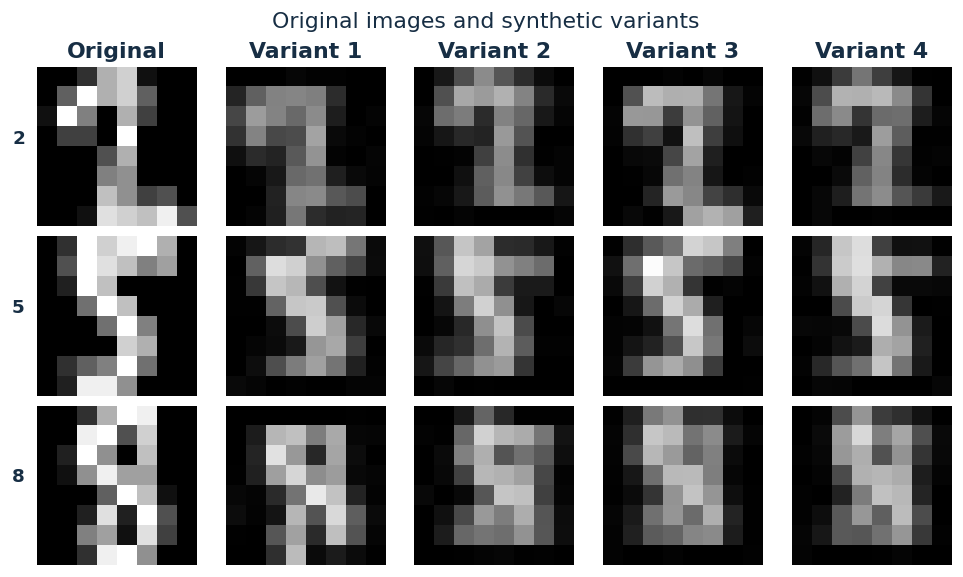

In [ ]:
# Show variants for three digit classes using examples from the training set.
examples = (2, 5, 8)
fig, axes = plt.subplots(len(examples), N_VARIANTS + 1, figsize=(8, 4.7), layout="constrained")
for row, digit in enumerate(examples):
    index = np.flatnonzero(y_train == digit)[0]
    start = index * N_VARIANTS
    variants = X_synthetic[start : start + N_VARIANTS]
    for col, (ax, image) in enumerate(zip(axes[row], [X_train[index], *variants])):
        ax.imshow(image, cmap="gray", vmin=0, vmax=MAX_PIXEL, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if col == 0:
            ax.set_ylabel(str(digit), rotation=0, labelpad=11, fontweight="semibold")
        if row == 0:
            ax.set_title("Original" if col == 0 else f"Variant {col}")
fig.suptitle("Original images and synthetic variants")
plt.show()

## 4. Training both models with the same SVM settings

We flatten each 8 × 8 image into a vector of 64 pixel intensities. `StandardScaler` puts each feature on a comparable scale. The support vector machine (`SVC`) uses an RBF kernel to learn nonlinear boundaries between digit classes.

Both models use the same settings (`kernel="rbf"`, `C=1.0`, and `gamma="scale"`). We fit the scaler and classifier on each model's own training set. We then run both models on the same 450 original test images. [Scikit-learn SVC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)

In [ ]:
def flatten_images(batch):
    # Flatten each image in the batch to a row of 64 pixel intensities.
    return np.asarray(batch).reshape(len(batch), 64)


def make_digit_model():
    # Use the same pipeline for both models. The scaler learns its statistics during fit.
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))


# Fit a separate instance of the pipeline on each version of the training set.
model_before = make_digit_model()
model_after = make_digit_model()
model_before.fit(flatten_images(X_train), y_train)
model_after.fit(flatten_images(X_train_augmented), y_train_augmented)

# Give both models the same test images in the same order.
test_features = flatten_images(X_test)
pred_before = model_before.predict(test_features)
pred_after = model_after.predict(test_features)
assert pred_before.shape == pred_after.shape == y_test.shape == (N_TEST,)
print("Both models are trained. Each produced 450 predictions on the shared test set.")

Both models are trained. Each produced 450 predictions on the shared test set.


## 5. Metrics on 450 test images

- **Accuracy** is the proportion of all predictions that are correct.
- **Precision** for a digit is the proportion of predictions of that digit that are correct.
- **Recall** for a digit is the proportion of its actual examples that the model identifies correctly.
- **F1** for a digit is the harmonic mean of its precision and recall.

For precision, recall, and F1, we calculate the score for each digit and average the ten scores equally (macro averaging). We report the difference between two percentages in **percentage points (pp)**.

,Before · 300,"After · 1,500",Change (pp)
Accuracy,92.44%,94.67%,+2.22
Precision (macro),92.80%,94.97%,+2.18
Recall (macro),92.38%,94.62%,+2.24
F1 (macro),92.45%,94.65%,+2.20


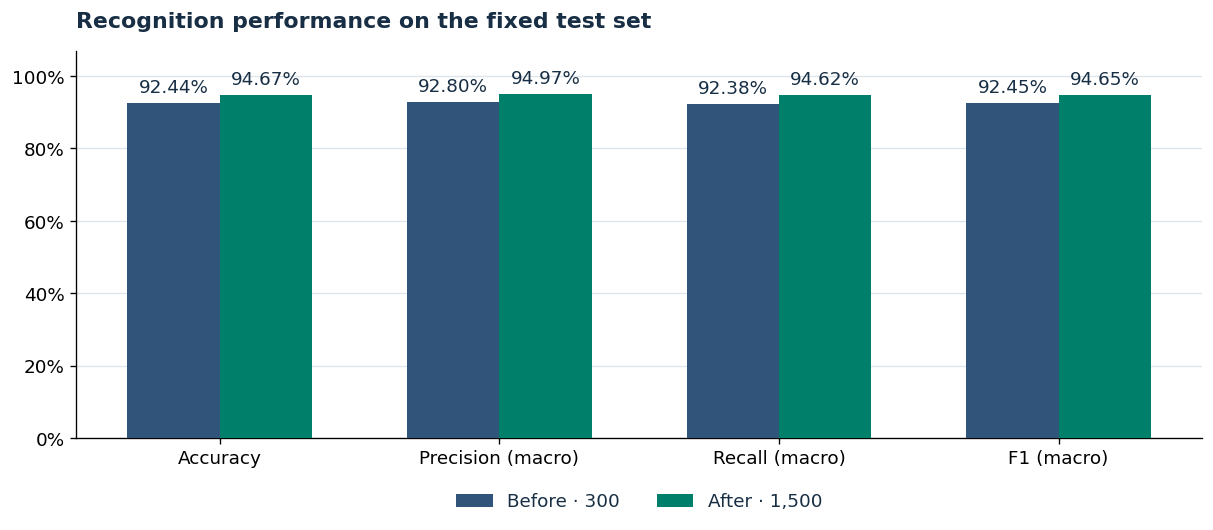

In [ ]:
def score_model(predictions):
    # Macro averaging gives every digit equal weight.
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions, labels=DIGIT_LABELS, average="macro", zero_division=0
    )
    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision,
        "Recall (macro)": recall,
        "F1 (macro)": f1,
    }


# Store metric values as proportions and display them as percentages.
results = pd.DataFrame({
    "Before · 300": score_model(pred_before),
    "After · 1,500": score_model(pred_after),
})
results["Change (pp)"] = (results.iloc[:, 1] - results.iloc[:, 0]) * 100

display(results.style.format({
    "Before · 300": "{:.2%}",
    "After · 1,500": "{:.2%}",
    "Change (pp)": "{:+.2f}",
}))

# Start the bars at zero so the size of each difference is shown in context.
fig, ax = plt.subplots(figsize=(10, 4.3), layout="constrained")
positions = np.arange(len(results))
width = 0.33
for offset, column, color in [
    (-width / 2, "Before · 300", BEFORE_COLOR),
    (width / 2, "After · 1,500", AFTER_COLOR),
]:
    values = results[column].to_numpy()
    bars = ax.bar(positions + offset, values, width=width, color=color, label=column, zorder=3)
    ax.bar_label(bars, labels=[f"{value:.2%}" for value in values], padding=4)

ax.set_xticks(positions, results.index)
ax.set_yticks(np.linspace(0, 1, 6))
ax.set_ylim(0, 1.07)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_title("Recognition performance on the fixed test set", loc="left", pad=14)
ax.legend(loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.23))
ax.grid(axis="y", color="#dce4ec", zorder=0)
plt.show()

## 6. Confusion matrices and results

Rows represent the actual digits, and columns represent the predicted digits. The diagonal shows correct predictions. For example, the cell at row 3 and column 8 counts how often the model predicted 8 for an actual 3. Both plots use the same color scale.

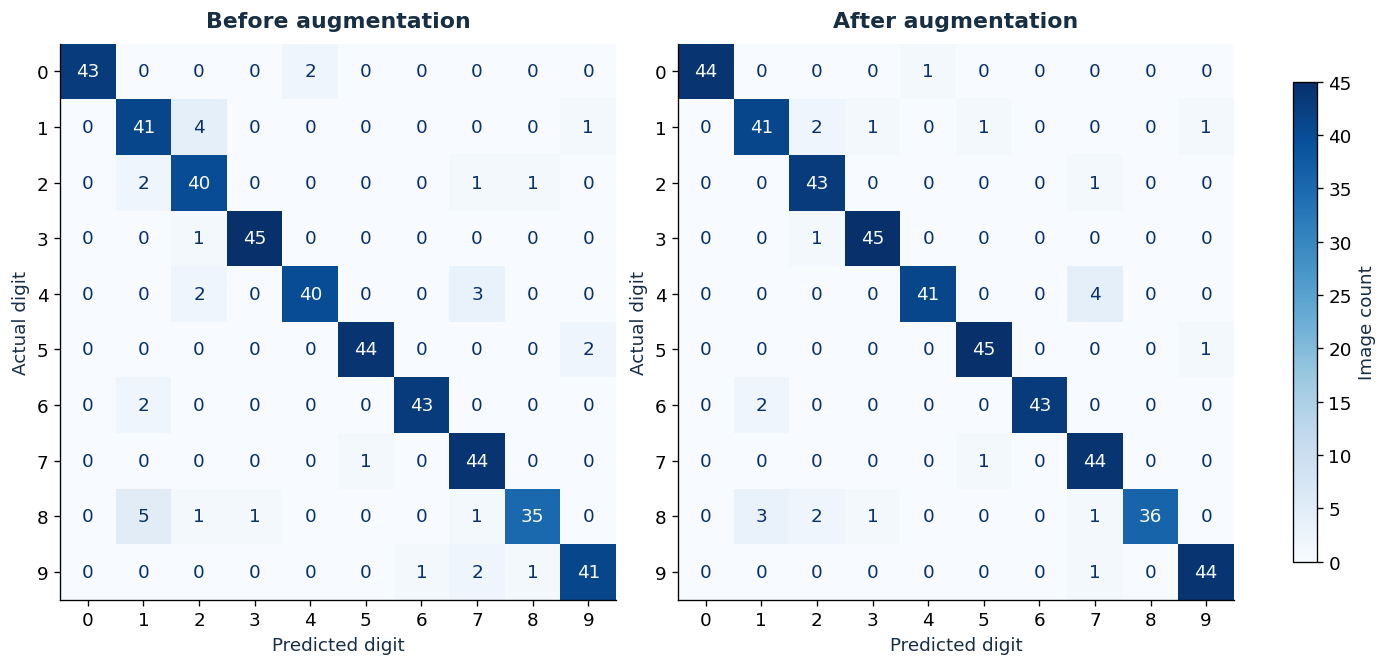

**Accuracy on the fixed test set: 92.44% → 94.67% (+2.22 pp).** Correct predictions: **416 → 426** out of 450. Augmentation corrected 13 errors and introduced 3 new ones.

In [ ]:
# Compute both matrices in the same digit order and check the total count.
matrix_before = confusion_matrix(y_test, pred_before, labels=DIGIT_LABELS)
matrix_after = confusion_matrix(y_test, pred_after, labels=DIGIT_LABELS)
assert matrix_before.sum() == matrix_after.sum() == N_TEST
color_max = max(matrix_before.max(), matrix_after.max())

# Plot both matrices with one shared color scale.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.3), layout="constrained")
for ax, title, matrix in zip(
    axes, ("Before augmentation", "After augmentation"), (matrix_before, matrix_after)
):
    matrix_display = ConfusionMatrixDisplay(matrix, display_labels=DIGIT_LABELS)
    matrix_display.plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": color_max},
    )
    ax.set_title(title, pad=10)
    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("Actual digit")
fig.colorbar(matrix_display.im_, ax=axes, shrink=0.84, label="Image count")
plt.show()

# Compare the models on each test image to count corrected and new errors.
correct_before = pred_before == y_test
correct_after = pred_after == y_test
fixed = np.count_nonzero(~correct_before & correct_after)
regressed = np.count_nonzero(correct_before & ~correct_after)
delta = results.loc["Accuracy", "Change (pp)"]

# Summarize the measured change, including a possible tie.
accuracy_before = f"{correct_before.mean():.2%}"
accuracy_after = f"{correct_after.mean():.2%}"
delta_text = f"{delta:+.2f}" if delta != 0 else "0.00"
display(Markdown(
    f"**Accuracy on the fixed test set: {accuracy_before} → {accuracy_after} ({delta_text} pp).** "
    f"Correct predictions: **{correct_before.sum()} → {correct_after.sum()}** out of {N_TEST}. "
    f"Augmentation corrected {fixed} errors and introduced {regressed} new ones."
))

**Scope of the result.** These metrics describe one fixed split of Digits. Performance on mouse drawings or other datasets may differ.

**Presentation plan for three speakers.** Speaker 1 introduces the dataset and shows examples of augmentation (sections 2–3). Speaker 2 explains the controlled comparison, metrics, and confusion matrices (sections 4–6). Speaker 3 compares predictions on a test example and draws a digit in Gradio (section 7).

## 7. Gradio demo

On the **Draw a digit** tab, draw one digit from 0 to 9 and click **Recognize**. The app shows both predictions and the 8 × 8 image passed to the models. Browser drawings can look different from the original Digits images, so either model may misclassify them.

On the **Test example** tab, select one of the 450 held-out images. The app shows its original pixels, actual digit, and both predictions. These examples are already included in the metrics above.

In [ ]:
# Pillow prepares the drawing. Gradio displays the canvas and predictions.
from PIL import ImageOps
import gradio as gr


def prepare_sketch(editor_value):
    # Gradio provides the editor's composite as a PIL image.
    if editor_value is None or editor_value["composite"] is None:
        return None

    composite = editor_value["composite"].convert("RGBA")
    background = Image.new("RGBA", composite.size, "white")
    grayscale = Image.alpha_composite(background, composite).convert("L")

    # Match Digits by converting dark strokes on white to bright strokes on black.
    ink = ImageOps.invert(grayscale)
    bounds = ink.point(lambda value: 255 if value > 16 else 0).getbbox()
    if bounds is None:
        return None

    # Fit the digit into a padded square while preserving its aspect ratio.
    digit = ink.crop(bounds)
    scale = 28 / max(digit.size)
    width, height = (max(1, round(size * scale)) for size in digit.size)
    digit = digit.resize((width, height), Image.Resampling.LANCZOS)
    canvas = Image.new("L", (32, 32), 0)
    canvas.paste(digit, ((32 - width) // 2, (32 - height) // 2))

    # Average blocks of pixels and scale intensities to the 0–16 range.
    small_image = canvas.resize((8, 8), Image.Resampling.BOX)
    pixels = np.asarray(small_image, dtype=np.float64)
    peak = pixels.max()
    if peak == 0:
        return None
    return (pixels / peak) * 16


def preview_pixels(pixels):
    # Enlarge the 8 × 8 image without smoothing so individual pixels are visible.
    grayscale = np.rint(pixels * (255 / 16)).astype(np.uint8)
    return Image.fromarray(grayscale).resize((192, 192), Image.Resampling.NEAREST)


def recognize_sketch(editor_value):
    # Show a hint and clear old predictions when the canvas is blank.
    pixels = prepare_sketch(editor_value)
    if pixels is None:
        return "", "", None, "Draw a digit on the canvas and click **Recognize**."

    # Pass the same 64 features to both models.
    features = flatten_images(pixels[np.newaxis, ...])
    before = str(model_before.predict(features)[0])
    after = str(model_after.predict(features)[0])
    return before, after, preview_pixels(pixels), ""


def show_test_example(number):
    # The interface numbers examples from 1, while array indices start at 0.
    index = int(number) - 1
    return (
        str(y_test[index]),
        str(pred_before[index]),
        str(pred_after[index]),
        preview_pixels(X_test[index]),
    )


# Check the blank canvas, preprocessed image format, and first test example.
assert prepare_sketch(None) is None
assert prepare_sketch({"composite": Image.new("RGBA", (64, 64), "white")}) is None
sample_sketch = Image.new("RGBA", (64, 64), "white")
sample_sketch.paste("black", (27, 10, 37, 54))
sample_pixels = prepare_sketch({"composite": sample_sketch})
assert sample_pixels.shape == (8, 8) and 0 <= sample_pixels.min() < sample_pixels.max() <= 16
assert show_test_example(1)[0] == str(y_test[0])

# Close the previous demo instance if the cell is rerun.
if "demo" in globals():
    demo.close()

# Build two tabs with side-by-side model predictions.
with gr.Blocks(title="Handwritten Digit Recognition") as demo:
    gr.Markdown("# Handwritten Digit Recognition")
    with gr.Tab("Draw a digit"):
        with gr.Row():
            with gr.Column():
                sketch = gr.ImageEditor(
                    value=Image.new("RGB", (280, 280), "white"),
                    label="Canvas",
                    type="pil",
                    image_mode="RGBA",
                    format="png",
                    sources=(),
                    transforms=(),
                    layers=False,
                    canvas_size=(280, 280),
                    fixed_canvas=True,
                    brush=gr.Brush(default_size=12, colors=["#000000"], color_mode="fixed"),
                    height=340,
                )
                with gr.Row():
                    recognize_button = gr.Button("Recognize", variant="primary")
                    clear_button = gr.Button("Clear")
            with gr.Column():
                with gr.Row():
                    sketch_before = gr.Textbox(label="Before augmentation", interactive=False)
                    sketch_after = gr.Textbox(label="After augmentation", interactive=False)
                sketch_preview = gr.Image(
                    label="Model input · 8 × 8", format="png", height=220, interactive=False
                )
                hint = gr.Markdown("Draw a digit on the canvas and click **Recognize**.")
        recognize_button.click(
            recognize_sketch,
            inputs=sketch,
            outputs=[sketch_before, sketch_after, sketch_preview, hint],
            api_name="recognize",
        )
        clear_button.click(
            lambda: (Image.new("RGB", (280, 280), "white"), *recognize_sketch(None)),
            outputs=[sketch, sketch_before, sketch_after, sketch_preview, hint],
            api_visibility="private",
        )

    with gr.Tab("Test example"):
        example_number = gr.Slider(1, len(y_test), value=1, step=1, label="Example number")
        first_true, first_before, first_after, first_preview = show_test_example(1)
        with gr.Row():
            test_true = gr.Textbox(value=first_true, label="Actual digit", interactive=False)
            test_before = gr.Textbox(value=first_before, label="Before augmentation", interactive=False)
            test_after = gr.Textbox(value=first_after, label="After augmentation", interactive=False)
        test_preview = gr.Image(
            value=first_preview,
            label="Original Digits image · 8 × 8",
            format="png",
            height=220,
            interactive=False,
        )
        example_number.change(
            show_test_example,
            inputs=example_number,
            outputs=[test_true, test_before, test_after, test_preview],
            api_name="test_example",
        )

Closing server running on port: 7860


### Launch the demo

Open the temporary Gradio link from the cell output in a new tab. The link is public and works while the demo is running. If the link service is unavailable, Colab will try to display the app below the cell.

In [ ]:
# Release the previous server's port before restarting.
if demo.is_running:
    demo.close()

# Show a temporary link in Colab and the local server address in Jupyter.
_, _, share_url = demo.launch(
    share=IN_COLAB, inline=False, prevent_thread_lock=True, show_error=True, ssr_mode=False
)

# If the link service is unavailable, display the local server inside Colab.
if IN_COLAB and not share_url:
    from google.colab import output

    output.serve_kernel_port_as_iframe(demo.server_port, height="740")

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6d69023fafba87e6b9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
